# Implementação do modelo de Naive-Bayes para classificação

## Importações iniciais

In [268]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, RocCurveDisplay, roc_curve, roc_auc_score, auc

## Implementação do _Naive Bayes_ para classificação

In [269]:
class NaiveBayes:
    def __init__(self,num_classes: int, alpha: float = 1.0)->None:
        self.num_classes = num_classes
        self.alpha = alpha
        self.class_priors = None
        self.features_log_prob = None
    def fit(self,X: np.ndarray, y: np.ndarray)->None:
        samples, features = X.shape
        contagens = np.bincount(y)
        self.class_priors = np.log(contagens / samples)
        y_one_hot = np.eye(self.num_classes)[y]

        counts = y_one_hot.T @ X
        Pwi = (counts + self.alpha)
        Pwi /= counts.sum(axis=1, keepdims=True)+self.alpha*features
        self.features_log_prob = np.log(Pwi)

    def predict(self, X: np.ndarray)->np.ndarray:
        scores = self.class_priors + X @ self.features_log_prob.T
        return np.argmax(scores, axis=1)

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        scores = self.class_priors + X @ self.features_log_prob.T
        exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
        probabilities = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
        return probabilities

Na implementação acima estou considerando um modelo de naive bayes multinomial, estou usando a proporção original das classes como prior. O modelo vai na prática calcular o MAP _(maximum a posteriori estimator)_.

\begin{aligned}
\mathbb{P}(y \ | \ x_1, x_2, ... , x_n) \propto \mathbb{P}(y) \cdot \prod_{i=1}^{n}{\mathbb{P}(x_i \ | \ y)^{x_i}}
\end{aligned}
Onde:
\begin{aligned}
\mathbb{P}(x_i \ | \ y) = \frac{N_{yi}+\alpha}{N_y + \alpha d}
\end{aligned}
E $\alpha$ denota o parâmetro de suavização, $d$ o número de features, $N_{yi}$ a contagem total da feature $i$ em todas as amostras da classe $y$ e $N_y$ a soma total da contagem de todas as features para a classe $y$.

## Modelagem

### Preparando o dataset

Link pro dataset original: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

In [270]:
df = pd.read_csv("spam.csv",encoding="latin-1",usecols=["v1","v2"])

In [271]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [272]:
df["HotEncoding"] = df["v1"].map({"ham":0, "spam": 1})
df.drop("v1",axis=1, inplace=True)

In [273]:
X_train, X_test, y_train, y_test = train_test_split(df["v2"],df["HotEncoding"],test_size=0.2,random_state=0)

In [274]:
vectorizer = TfidfVectorizer()

In [275]:
X_train = vectorizer.fit_transform(X_train)

In [276]:
X_test = vectorizer.transform(X_test)

### Teste dos modelos

#### Naive-Bayes Bruto

In [277]:
nbb = NaiveBayes(num_classes=2)

In [278]:
nbb.fit(X_train, y_train)

In [279]:
y_pred = nbb.predict(X_test)

In [280]:
metricas = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)],
    index=["Acurácia","Precisão","Recall","F1-Score"],
    columns=["NaiveBayes Bruto"]
)

#### NaiveBayes Scikit-Learn

In [281]:
nbsk = MultinomialNB()

In [282]:
nbsk.fit(X_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [283]:
y_pred = nbsk.predict(X_test)

In [284]:
msk = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)],
    index=["Acurácia","Precisão","Recall","F1-Score"],
    columns=["NaiveBayes Scikit"]
)

In [285]:
metricas = pd.concat([metricas,msk],axis=1)

#### Regressão logística

In [286]:
lg = LogisticRegression()

In [287]:
lg.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [288]:
y_pred = lg.predict(X_test)

In [289]:
msk = pd.DataFrame(
    data=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)],
    index=["Acurácia","Precisão","Recall","F1-Score"],
    columns=["Regressão Logística"]
)

In [290]:
metricas = pd.concat([metricas,msk],axis=1)

### Curva ROC e métricas

In [291]:
y_pred = nbb.predict_proba(X_test)

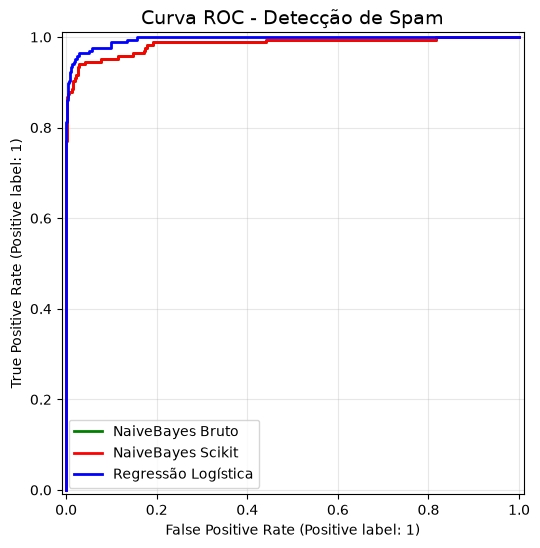

In [292]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred[:, 1],
    ax=ax,
    name="NaiveBayes Bruto",
    curve_kwargs={"color": "green", "linewidth": 2, "label": "NaiveBayes Bruto"}
)

RocCurveDisplay.from_estimator(
    nbsk, 
    X_test, 
    y_test, 
    ax=ax, 
    name="NaiveBayes Scikit",
    curve_kwargs={"color": "red", "linewidth": 2, "label": "NaiveBayes Scikit"}
)
RocCurveDisplay.from_estimator(
    lg, 
    X_test, 
    y_test, 
    ax=ax, 
    name="Regressão Logística",
    curve_kwargs={"color": "blue", "linewidth": 2, "label": "Regressão Logística"}
)

plt.title('Curva ROC - Detecção de Spam', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

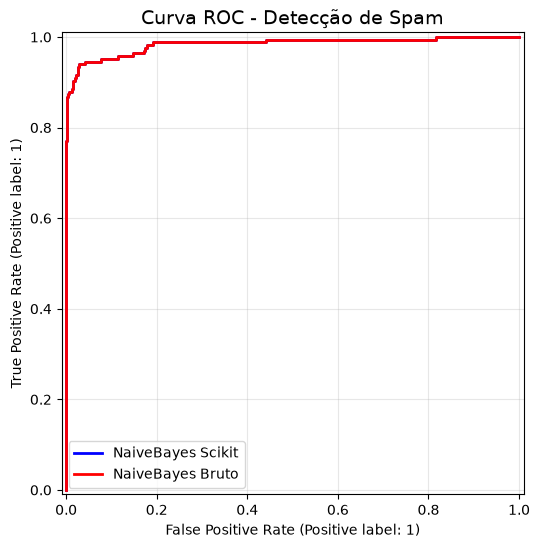

In [293]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    nbsk, 
    X_test, 
    y_test, 
    ax=ax, 
    name="NaiveBayes Scikit",
    curve_kwargs={"color": "blue", "linewidth": 2, "label": "NaiveBayes Scikit"}
)
RocCurveDisplay.from_predictions(
    y_test,
    y_pred[:, 1],
    ax=ax,
    name="NaiveBayes Bruto",
    curve_kwargs={"color": "red", "linewidth": 2, "label": "NaiveBayes Bruto"}
)

plt.title('Curva ROC - Detecção de Spam', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [294]:
metricas

,NaiveBayes Bruto,NaiveBayes Scikit,Regressão Logística
Acurácia,0.947982,0.947982,0.965022
Precisão,1.000000,1.000000,1.000000
Recall,0.650602,0.650602,0.765060
F1-Score,0.788321,0.788321,0.866894


In [295]:
print("Auc dos modelos: \nNaiveBayes Bruto: {:.4f}\nNaiveBayes Scikit: {:.4f}\nRegressão Logística: {:.4f}".format(
    roc_auc_score(y_test, nbb.predict_proba(X_test)[:, 1]),
    roc_auc_score(y_test, nbsk.predict_proba(X_test)[:, 1]),
    roc_auc_score(y_test, lg.predict_proba(X_test)[:, 1])
))

Auc dos modelos: 
NaiveBayes Bruto: 0.9844
NaiveBayes Scikit: 0.9844
Regressão Logística: 0.9953
